# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset dapat diperoleh dari berbagai sumber, seperti public repositories (*Kaggle*, *UCI ML Repository*, *Open Data*) atau data primer yang Anda kumpulkan sendiri.


**Dataset yang digunakan: Telco Customer Churn**

- **Sumber**: Kaggle - *Telco Customer Churn* (IBM sample data). Salinan CSV disimpan di `../telco_churn_raw/Telco-Customer-Churn.csv`.
- **Jumlah data**: 7.043 baris, 21 kolom (data tabular / terstruktur).
- **Tujuan**: memprediksi apakah pelanggan akan berhenti berlangganan (*churn*), yaitu **klasifikasi biner** pada kolom target `Churn`.
- **Fitur**: demografi (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), layanan (`PhoneService`, `InternetService`, `OnlineSecurity`, dst.), kontrak & pembayaran (`Contract`, `PaymentMethod`, `PaperlessBilling`), serta numerik (`tenure`, `MonthlyCharges`, `TotalCharges`).

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
print('Library berhasil diimpor')

Library berhasil diimpor


# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [2]:
# Lokasi dataset mentah (relatif terhadap folder preprocessing/)
RAW_PATH = '../telco_churn_raw/Telco-Customer-Churn.csv'

df = pd.read_csv(RAW_PATH)
print('Ukuran dataset (baris, kolom):', df.shape)
df.head()

Ukuran dataset (baris, kolom): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

## 4.1 Struktur & statistik dasar

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Kolom `TotalCharges` bertipe `object` padahal seharusnya numerik. Kemungkinan ada nilai kosong berupa spasi. Kita cek pada langkah berikut.

In [5]:
# Cek missing value (termasuk string kosong/spasi) dan duplikasi
print('Missing value (NaN) per kolom:')
print(df.isna().sum()[df.isna().sum() > 0])

blank_total = df['TotalCharges'].astype(str).str.strip().eq('').sum()
print('\nJumlah TotalCharges berisi spasi kosong:', blank_total)
print('Jumlah baris duplikat:', df.duplicated().sum())
print('Jumlah customerID duplikat:', df['customerID'].duplicated().sum())

# Baris dengan TotalCharges kosong
df[df['TotalCharges'].astype(str).str.strip().eq('')][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Missing value (NaN) per kolom:
Series([], dtype: int64)

Jumlah TotalCharges berisi spasi kosong: 11
Jumlah baris duplikat: 0
Jumlah customerID duplikat: 0


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Seluruh baris dengan `TotalCharges` kosong memiliki `tenure = 0` (pelanggan baru yang belum ditagih), sehingga nilai yang masuk akal untuk mengisinya adalah **0**.

## 4.2 Distribusi target

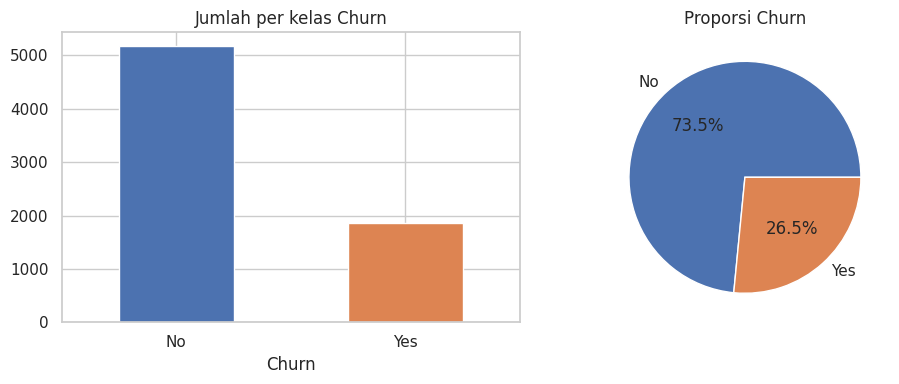

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df['Churn'].value_counts().plot(kind='bar', ax=ax[0], color=['#4C72B0', '#DD8452'])
ax[0].set_title('Jumlah per kelas Churn'); ax[0].set_xlabel('Churn'); ax[0].tick_params(axis='x', rotation=0)
df['Churn'].value_counts(normalize=True).plot(kind='pie', autopct='%1.1f%%', ax=ax[1], colors=['#4C72B0', '#DD8452'])
ax[1].set_ylabel(''); ax[1].set_title('Proporsi Churn')
plt.tight_layout(); plt.show()

Data cukup **tidak seimbang** (sekitar 73% *No* vs 27% *Yes*). Karena itu pembagian data nanti memakai `stratify` agar proporsi kelas tetap terjaga.

## 4.3 Fitur numerik

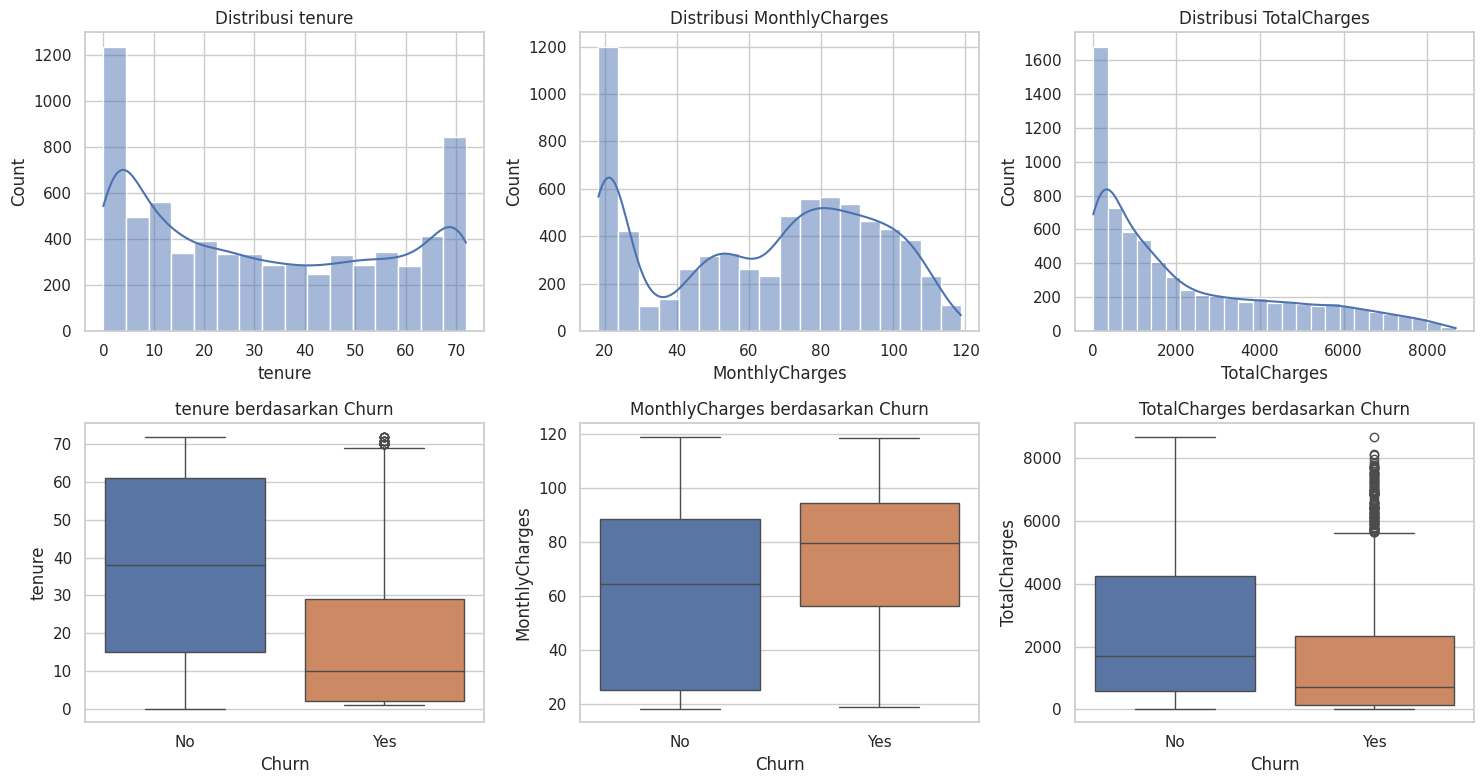

In [7]:
tmp = df.copy()
tmp['TotalCharges'] = pd.to_numeric(tmp['TotalCharges'], errors='coerce')
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, c in enumerate(num_cols):
    sns.histplot(tmp[c].dropna(), kde=True, ax=axes[0, i], color='#4C72B0')
    axes[0, i].set_title(f'Distribusi {c}')
    sns.boxplot(data=tmp, x='Churn', y=c, ax=axes[1, i], palette=['#4C72B0', '#DD8452'])
    axes[1, i].set_title(f'{c} berdasarkan Churn')
plt.tight_layout(); plt.show()

Pelanggan yang churn cenderung memiliki `tenure` pendek dan `MonthlyCharges` lebih tinggi.

## 4.4 Fitur kategorikal vs Churn

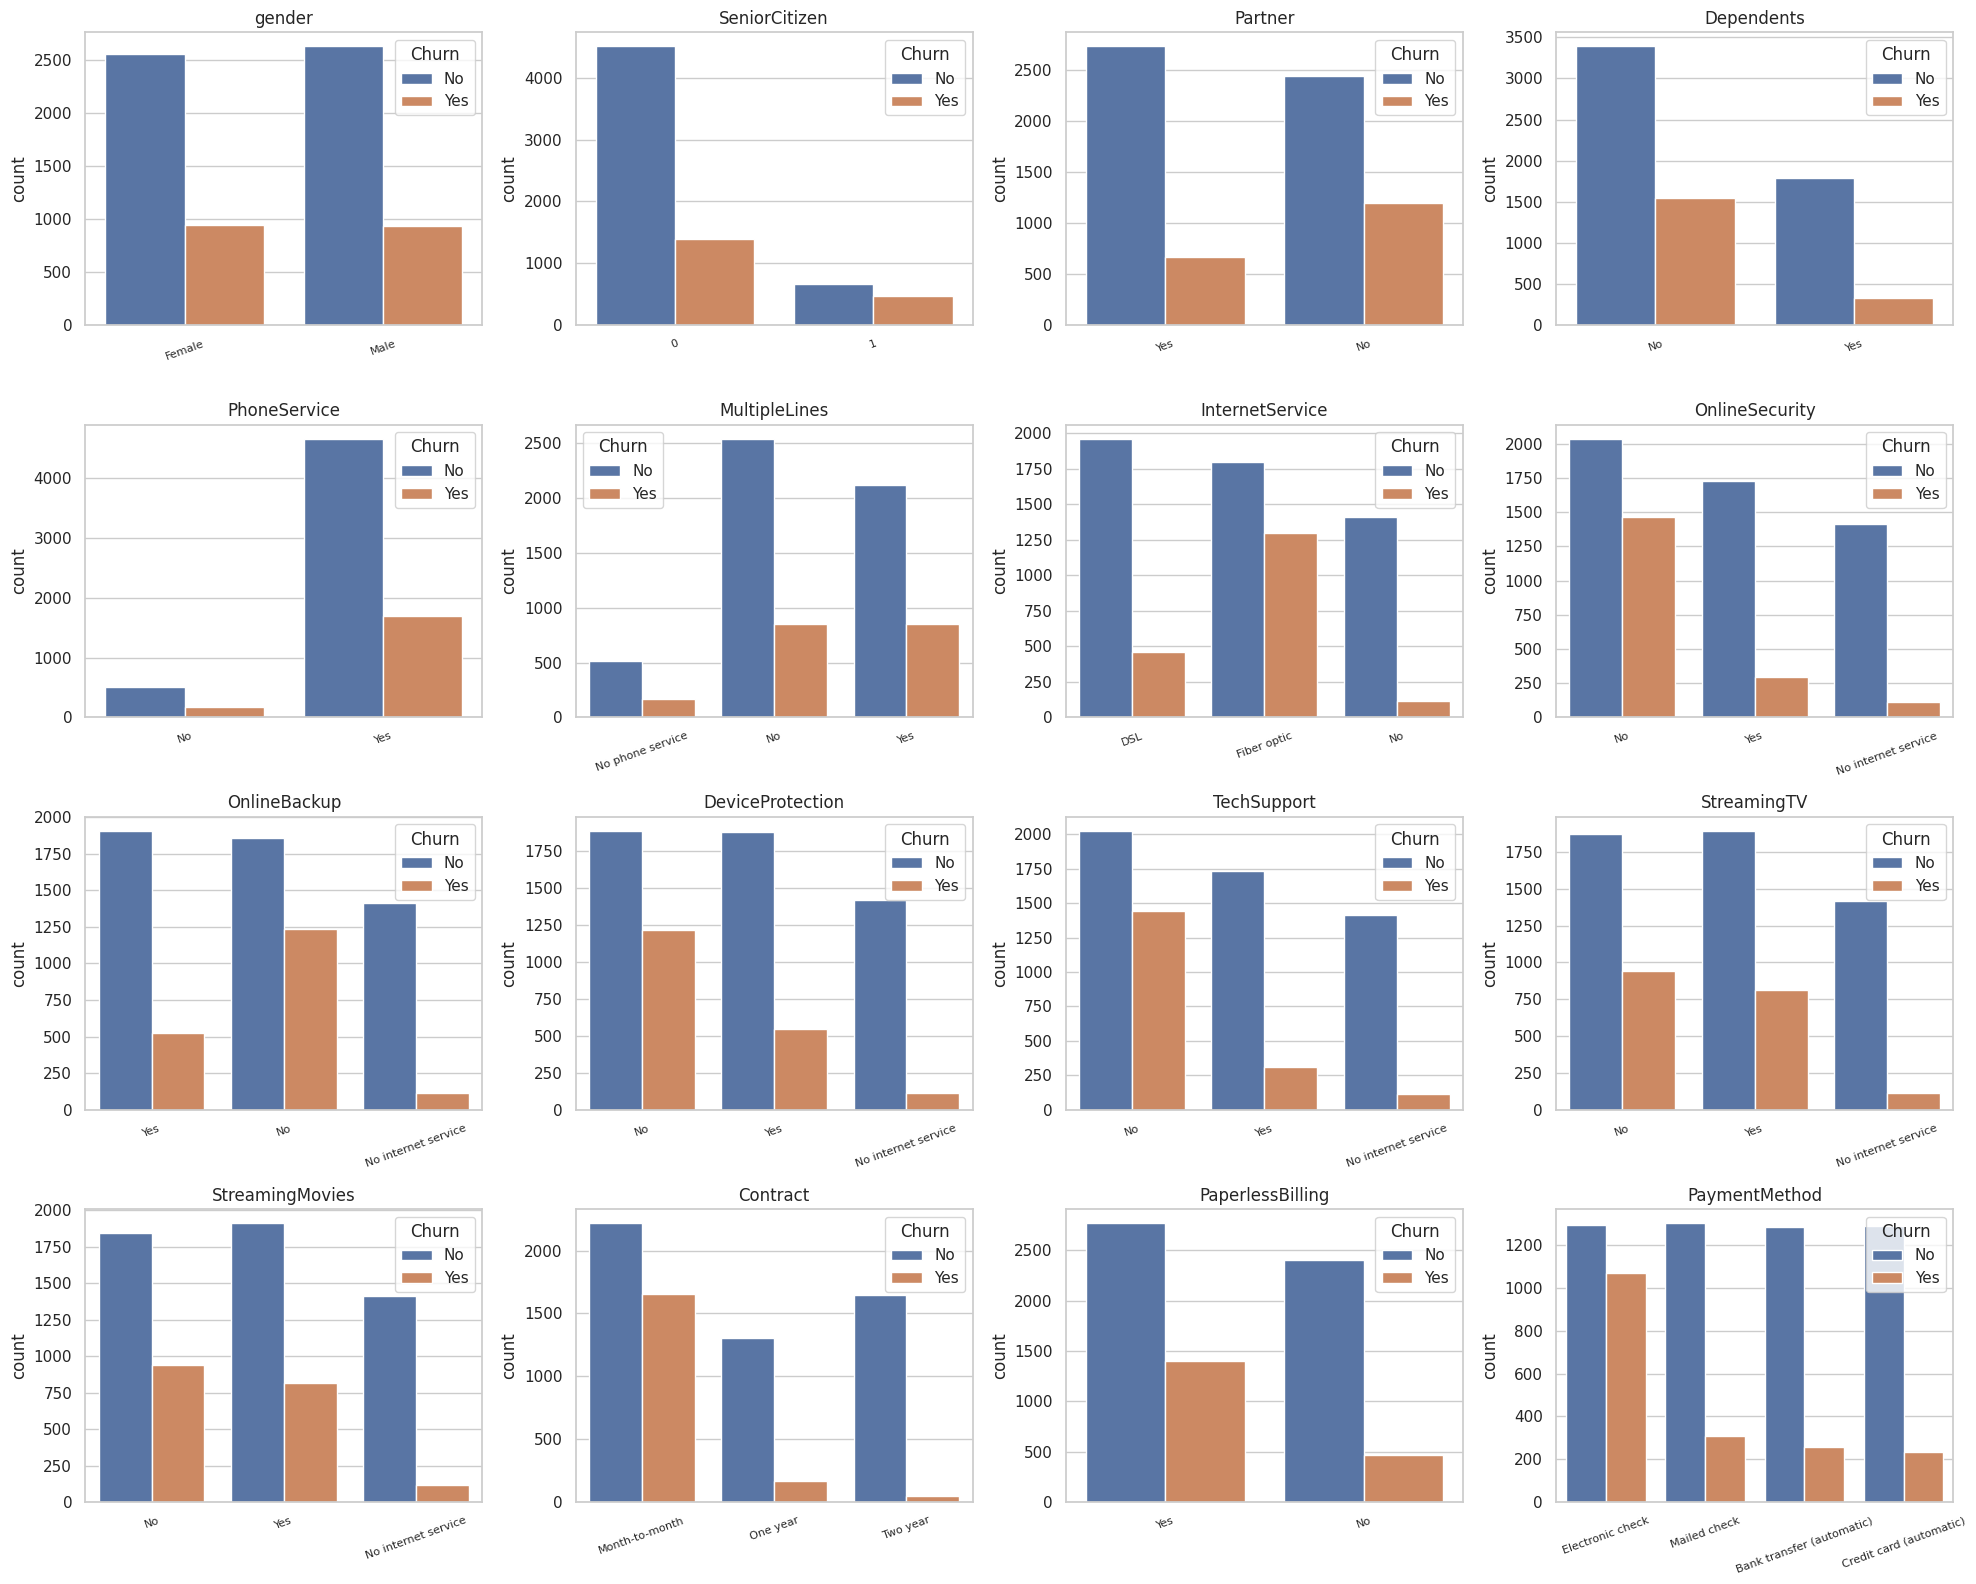

In [8]:
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
            'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
            'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, c in zip(axes.ravel(), cat_cols):
    sns.countplot(data=df, x=c, hue='Churn', ax=ax, palette=['#4C72B0', '#DD8452'])
    ax.set_title(c); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20, labelsize=8)
plt.tight_layout(); plt.show()

In [9]:
# Churn rate (%) untuk fitur yang paling berpengaruh
for c in ['Contract', 'InternetService', 'PaymentMethod']:
    rate = df.groupby(c)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(1)
    print(f'Churn rate per {c} (%):')
    print(rate.to_string())
    print()

Churn rate per Contract (%):
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8

Churn rate per InternetService (%):
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4

Churn rate per PaymentMethod (%):
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1



Temuan utama: kontrak **Month-to-month**, layanan internet **Fiber optic**, dan pembayaran **Electronic check** memiliki tingkat churn jauh lebih tinggi dibanding kategori lainnya.

## 4.5 Korelasi fitur numerik

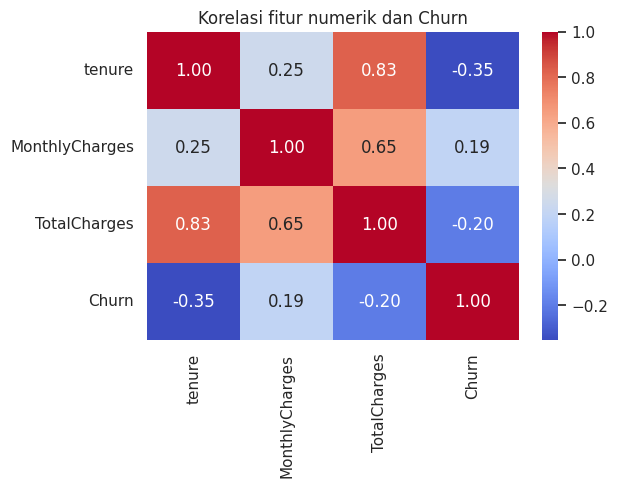

In [10]:
corr_df = tmp[num_cols].copy()
corr_df['Churn'] = (tmp['Churn'] == 'Yes').astype(int)
plt.figure(figsize=(6, 4))
sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi fitur numerik dan Churn'); plt.show()

`tenure` dan `TotalCharges` berkorelasi kuat (wajar, karena total tagihan bergantung pada lama berlangganan).

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

## 5.1 Menyalin data & menangani missing value

In [11]:
data = df.copy()

# TotalCharges: ubah ke numerik, spasi kosong -> NaN -> isi 0 (pelanggan baru dengan tenure = 0)
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
print('Missing sebelum penanganan :', data['TotalCharges'].isna().sum())
data['TotalCharges'] = data['TotalCharges'].fillna(0)
print('Missing sesudah penanganan :', data['TotalCharges'].isna().sum())
print('Total missing seluruh data  :', data.isna().sum().sum())

Missing sebelum penanganan : 11
Missing sesudah penanganan : 0
Total missing seluruh data  : 0


## 5.2 Menghapus kolom identitas & data duplikat

In [12]:
# customerID hanya pengenal unik, tidak informatif untuk model
data = data.drop(columns=['customerID'])

before = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print(f'Baris sebelum: {before} | sesudah drop_duplicates: {len(data)} | dihapus: {before - len(data)}')

Baris sebelum: 7043 | sesudah drop_duplicates: 7021 | dihapus: 22


## 5.3 Deteksi outlier (IQR)

In [13]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

for c in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    print(f'{c:15s} jumlah outlier (IQR): {iqr_outliers(data[c])}')

tenure          jumlah outlier (IQR): 0
MonthlyCharges  jumlah outlier (IQR): 0
TotalCharges    jumlah outlier (IQR): 0


Tidak ditemukan outlier pada fitur numerik, sehingga **tidak ada data yang dibuang** pada tahap ini.

## 5.4 Encoding data kategorikal

In [14]:
# a) Target: Yes/No -> 1/0
data['Churn'] = data['Churn'].map({'Yes': 1, 'No': 0})

# b) Samakan kategori 'No internet service' / 'No phone service' menjadi 'No'
replace_cols = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']
for c in replace_cols:
    data[c] = data[c].replace({'No internet service': 'No', 'No phone service': 'No'})

# c) Kolom biner -> 0/1
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling'] + replace_cols
for c in binary_cols:
    data[c] = data[c].map({'Yes': 1, 'No': 0})
data['gender'] = data['gender'].map({'Male': 1, 'Female': 0})

# d) Kolom multi-kategori -> one-hot encoding
data = pd.get_dummies(data, columns=['InternetService', 'Contract', 'PaymentMethod'], dtype=int)

print('Sisa kolom bertipe object:', data.select_dtypes(include='object').columns.tolist())
print('Total missing setelah encoding:', int(data.isna().sum().sum()))
print('Ukuran data setelah encoding:', data.shape)
data.head()

Sisa kolom bertipe object: []
Total missing setelah encoding: 0
Ukuran data setelah encoding: (7021, 27)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,1,0,0,0,0,1,0


## 5.5 Pembagian data latih & uji

Data dibagi **sebelum** standarisasi agar *scaler* hanya mempelajari statistik data latih (mencegah *data leakage*).

In [15]:
X = data.drop(columns=['Churn'])
y = data['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Proporsi churn train:', round(y_train.mean(), 3), '| test:', round(y_test.mean(), 3))

Train: (5616, 26) | Test: (1405, 26)
Proporsi churn train: 0.264 | test: 0.265


## 5.6 Standarisasi fitur numerik

In [16]:
scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])   # fit hanya pada data latih
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

# Semua fitur dijadikan float64 agar skema input model konsisten saat serving
X_train = X_train.astype('float64')
X_test = X_test.astype('float64')

X_train[scale_cols].describe().loc[['mean', 'std']].round(3)

,tenure,MonthlyCharges,TotalCharges
mean,0.0,-0.0,-0.0
std,1.0,1.0,1.0


## 5.7 Menyimpan dataset hasil preprocessing

In [17]:
OUT_DIR = 'telco_churn_preprocessing'
os.makedirs(OUT_DIR, exist_ok=True)

train_df = X_train.copy()
train_df['Churn'] = y_train.values
test_df = X_test.copy()
test_df['Churn'] = y_test.values

train_df.to_csv(f'{OUT_DIR}/train.csv', index=False)
test_df.to_csv(f'{OUT_DIR}/test.csv', index=False)

print('Tersimpan:')
for f in sorted(os.listdir(OUT_DIR)):
    print(' -', f'{OUT_DIR}/{f}')
print('Siap dilatih -> train:', train_df.shape, '| test:', test_df.shape)
print('Kolom fitur :', list(X_train.columns))

Tersimpan:
 - telco_churn_preprocessing/test.csv
 - telco_churn_preprocessing/train.csv
Siap dilatih -> train: (5616, 27) | test: (1405, 27)
Kolom fitur : ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


## Kesimpulan

Seluruh tahapan sesuai template dikerjakan secara manual: **pemuatan data -> EDA -> preprocessing**. Dataset yang sudah bersih, ter-encode, dan terstandarisasi disimpan sebagai `train.csv` dan `test.csv` di folder `telco_churn_preprocessing/`, siap dipakai untuk pelatihan model pada Kriteria 2.